In [1]:
%run sem2.py

In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [4]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60 ~ norm; ex1 ~ norm; ex2 ~ norm; ex3 ~ norm"
model = sem2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(2000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.8071, s1: 8.4811, s2: 1.3479
Iter 100 | loss: 4.7852, s1: 6.8527, s2: 4.1350
Iter 200 | loss: 3.6511, s1: 6.4949, s2: 5.6876
Iter 300 | loss: 2.7472, s1: 6.1601, s2: 6.8259
Iter 400 | loss: 2.0608, s1: 4.8484, s2: 5.5753
Iter 500 | loss: 1.7657, s1: 4.4541, s2: 5.3768
Iter 600 | loss: 1.7479, s1: 3.4238, s2: 3.3517
Iter 700 | loss: 1.3911, s1: 2.9697, s2: 3.1571
Iter 800 | loss: 1.2230, s1: 2.6307, s2: 2.8154
Iter 900 | loss: 1.2455, s1: 2.6360, s2: 2.7810
Iter 1000 | loss: 1.3238, s1: 2.5560, s2: 2.4643
Iter 1100 | loss: 1.2995, s1: 2.6069, s2: 2.6148
Iter 1200 | loss: 1.1581, s1: 2.4184, s2: 2.5206
Iter 1300 | loss: 1.3379, s1: 2.6173, s2: 2.5588
Iter 1400 | loss: 1.4047, s1: 2.5713, s2: 2.3332
Iter 1500 | loss: 1.1783, s1: 2.5551, s2: 2.7536
Iter 1600 | loss: 1.4855, s1: 2.7668, s2: 2.5627
Iter 1700 | loss: 1.4702, s1: 2.7968, s2: 2.6533
Iter 1800 | loss: 1.2873, s1: 2.8359, s2: 3.0972
Iter 1900 | loss: 1.1857, s1: 2.5094, s2: 2.6474
Iter 2000 | loss: 1.5811, s1: 2.

In [6]:
beta = [model.layer[node].weight[0][0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]

[1.0, 1.9765494068423435, 1.818139469845669]

In [7]:
# Linear factor model (same as lavaan package example)
# Loss function: log-likelihood
formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
formula_epscov = "e15 ~ norm; e24 ~ norm; e26 ~ norm; e37 ~ norm; e48 ~ norm; e68 ~ norm;"
formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26 + e68; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
formula2 = formula_epsx + formula_epsy + formula_epsdem + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [8]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]
sample_cov = torch.cov(torch.t(x))

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [9]:
# Maximum likelihood (use sample from model to estimate variance)
model2 = sem2(formula2)
observed_index = [list(model2.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model2.parameters(), lr=5e-2)
model2.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model2(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    # loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model2.layer["x1"].weight[0][0]
    dem60_scale = model2.layer["y1"].weight[0][0]
    dem65_scale = model2.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model2.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model2.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model2.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 384.9202, s1: 2.8119, s2: 2.4617
[-0.36737984 -0.05800273 -0.05099481]
Iter 1000 | loss: 21.2684, s1: 2.8119, s2: 2.4617
[1.50288022 0.56725198 0.82919592]
Iter 2000 | loss: 21.3209, s1: 2.8119, s2: 2.4617
[1.51377916 0.53910708 0.8530091 ]
Iter 3000 | loss: 21.2461, s1: 2.8119, s2: 2.4617
[1.46907878 0.60360408 0.85510755]
Iter 4000 | loss: 21.2719, s1: 2.8119, s2: 2.4617
[1.43704343 0.52836812 0.83366358]
Iter 5000 | loss: 21.2922, s1: 2.8119, s2: 2.4617
[1.47129059 0.59831643 0.86461431]


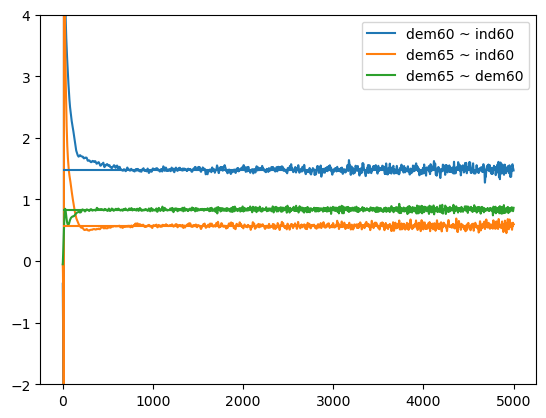

In [10]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [11]:
# Energy loss minimization (100 * data size to estimate loss, normalize x first)
model3 = sem2(formula2)
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model3.parameters(), lr=1e-2)
model3.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model3(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model3.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model3.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model3.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model3.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model3.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model3.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.6547, s1: 9.8397, s2: 2.3701
[-12.91451073   3.30655122   0.43316364]
Iter 1000 | loss: 2.1958, s1: 4.4461, s2: 4.5006
[2.08965421 0.93874836 0.67393363]
Iter 2000 | loss: 2.1812, s1: 4.4217, s2: 4.4809
[1.68870342 0.72008628 0.79687959]
Iter 3000 | loss: 2.1972, s1: 4.4164, s2: 4.4384
[1.68046629 0.75026357 0.81737179]
Iter 4000 | loss: 2.2035, s1: 4.4494, s2: 4.4918
[1.80287766 0.65838647 0.84776235]
Iter 5000 | loss: 2.1913, s1: 4.4280, s2: 4.4734
[1.71877384 0.6641444  0.84942675]


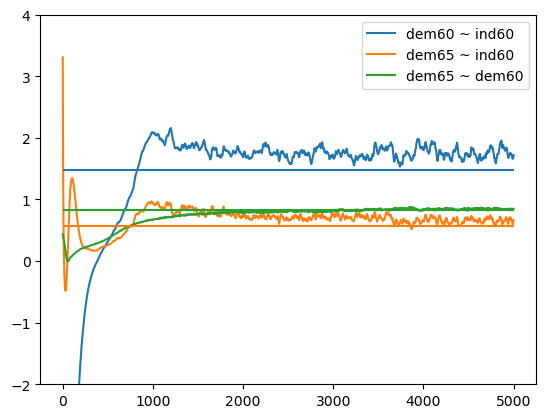

In [12]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()